# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
%pwd

'/home/mfixman/Dropbox/continuous/TP/MyPyCop'

In [5]:
# data = pandas.concat([
    # pandas.read_csv(
        # 'results/old/scores_test.csv',
    # ),
    # pandas.read_csv(
        # 'results/old/csscores_test.csv',
    # )
# ]).set_index(['problem', 'strategy'])

data = pandas.read_csv('results/sat_t1_SYN.csv', index_col = ['problem', 'strategy'])

In [6]:
strategies = data.index.get_level_values('strategy').unique()
strategies

Index(['FirstAction', 'LeanCopCut', 'SATSolve', 'SATSolveGuided',
       'SATSolveGuidedProbeConflicts', 'SATSolveGuidedForcedTrue',
       'SATSolveGuidedEVSIDS', 'SATSolveGuidedShort', 'SATSolveGuidedFast',
       'SATSolveLiteral'],
      dtype='object', name='strategy')

In [7]:
# problems = data.xs(level = 'strategy', key = 'SATSolveGuided').index.str[:3].unique()
# data = data[data.index.get_level_values('problem').str[:3].isin(problems)]
# problems

In [8]:
# data = data.groupby(level = 'problem').filter(lambda x: x.solved.count() == len(strategies))

# Analysing

In [9]:
control = ['FirstAction', 'LeanCopCut']

In [10]:
data[data.solved]

status  solved  steps  time_ms  \
problem    strategy                                                       
SYN000+1.p FirstAction                   solved    True    8.0      1.0   
           LeanCopCut                    solved    True    8.0      1.0   
           SATSolve                      solved    True  598.0    202.0   
           SATSolveGuided                solved    True  610.0    248.0   
           SATSolveGuidedProbeConflicts  solved    True  606.0    259.0   
...                                         ...     ...    ...      ...   
SYN981+1.p SATSolveGuidedForcedTrue      solved    True   13.0      2.0   
           SATSolveGuidedEVSIDS          solved    True   13.0      1.0   
           SATSolveGuidedShort           solved    True   13.0      1.0   
           SATSolveGuidedFast            solved    True   13.0      1.0   
           SATSolveLiteral               solved    True   15.0      2.0   

                                                  info  error  
problem    strategy                                            
SYN000+1.p FirstAction                         Theorem    NaN  
           LeanCopCut                          Theorem    NaN  
           SATSolve                      Theorem (SAT)    NaN  
           SATSolveGuided                Theorem (SAT)    NaN  
           SATSolveGuidedProbeConflicts  Theorem (SAT)    NaN  
...                                                ...    ...  
SYN981+1.p SATSolveGuidedForcedTrue      Theorem (SAT)    NaN  
           SATSolveGuidedEVSIDS          Theorem (SAT)    NaN  
           SATSolveGuidedShort           Theorem (SAT)    NaN  
           SATSolveGuidedFast            Theorem (SAT)    NaN  
           SATSolveLiteral               Theorem (SAT)    NaN  

[4734 rows x 6 columns]

In [11]:
data[data.solved].groupby(level = 1).size()

strategy
FirstAction                     486
LeanCopCut                      489
SATSolve                        461
SATSolveGuided                  450
SATSolveGuidedEVSIDS            463
SATSolveGuidedFast              460
SATSolveGuidedForcedTrue        457
SATSolveGuidedProbeConflicts    453
SATSolveGuidedShort             464
SATSolveLiteral                 551
dtype: int64

In [12]:
solved = data['solved'].unstack('strategy')

In [13]:
solved[solved.sum(axis = 1) == 1].sum(axis = 0)

strategy
FirstAction                      4
LeanCopCut                       1
SATSolve                         0
SATSolveGuided                   0
SATSolveGuidedEVSIDS             0
SATSolveGuidedFast               1
SATSolveGuidedForcedTrue         1
SATSolveGuidedProbeConflicts     0
SATSolveGuidedShort              0
SATSolveLiteral                 37
dtype: int64

# Results

<Axes: xlabel='strategy'>

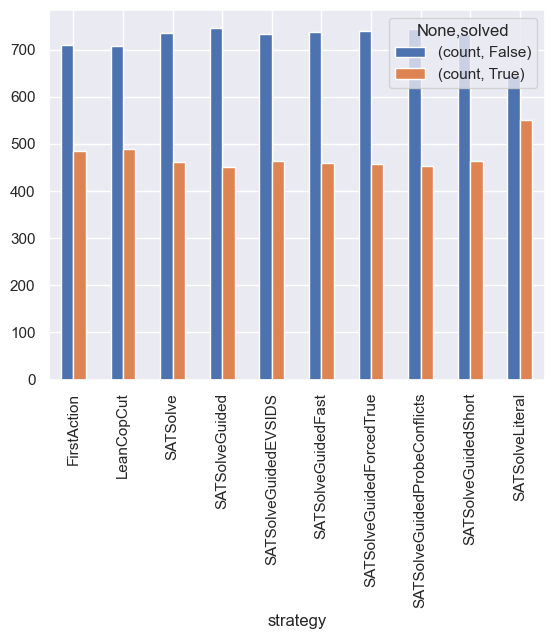

In [14]:
data.groupby(level = 'strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

<Axes: xlabel='strategy'>

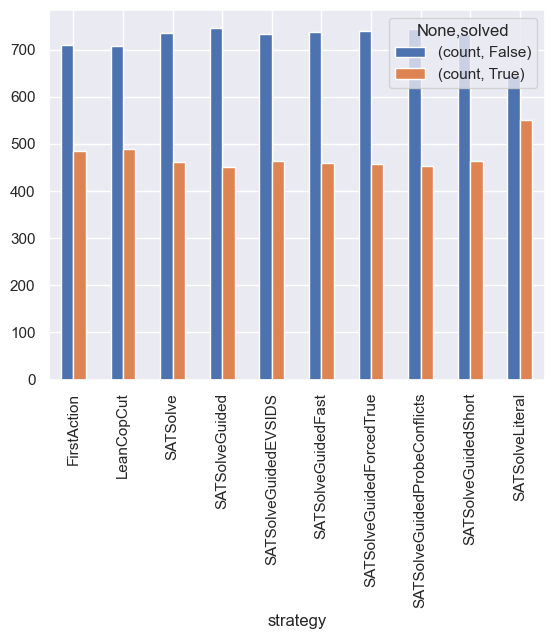

In [15]:
data[data.index.get_level_values('problem').str[:3] == 'SYN'].groupby(level = 'strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

<Axes: xlabel='winner', ylabel='loser'>

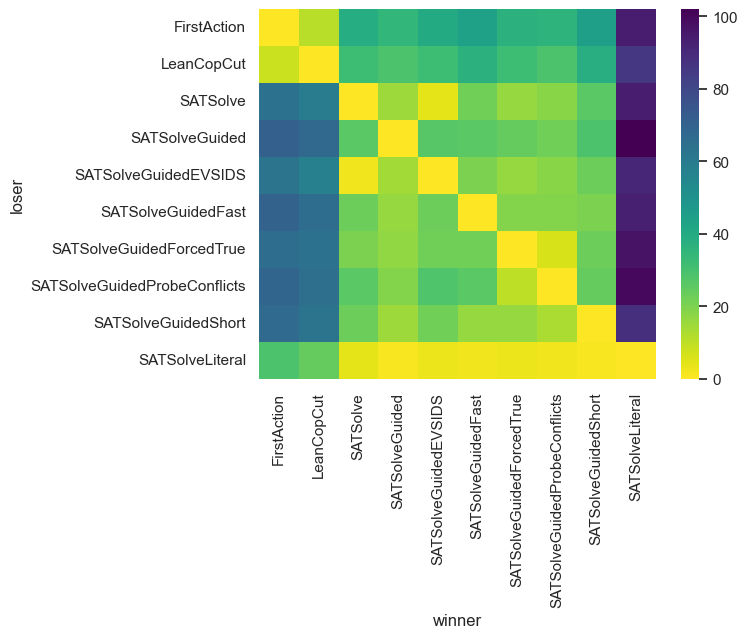

In [16]:
merged = pandas.merge(
    data.reset_index('strategy'),
    data.reset_index('strategy'),
    left_index = True,
    right_index = True,
    suffixes = ('_left', '_right'),
).set_index(['strategy_left', 'strategy_right'], append = True)

# merged = merged[merged.strategy_left < merged.strategy_right]
results = (
    merged
    [~merged.solved_left & merged.solved_right]
    .reset_index(['strategy_left', 'strategy_right'])
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'loser', columns = 'winner')
)

seaborn.heatmap(results, cmap = 'viridis_r')

In [17]:
tr = {}
for problem in merged.index.get_level_values('problem').unique():
    base = problem[0:3]
    a = open(f'/home/mfixman/TP/TPTP/Problems/{base}/{problem}').readlines(100000)
    tr[problem] = sum(1 for x in a if x and not x.isspace() and x[0] != '%')

tr = Series(tr, name = 'length')
tr.index.name = 'problem'

In [18]:
statistics = (
    merged
    .xs('SATSolve', level = 'strategy_right')
    # .loc[lambda x: ~x.solved_left & x.solved_right]
    .loc[lambda x: x.index.get_level_values('problem').str.contains('-')]
    # .loc[lambda x: x.index.get_level_values('strategy_left') != 'SATSolve']
    # .groupby(level = 'problem')
    # .filter(lambda x: len(x) == 3)
    .join(tr)
    .sort_values(['steps_right', 'length'], kind = 'stable')
)
statistics.loc[lambda x: (x.steps_right == 1) & (x.steps_left > 10)].sort_values('steps_left').head(40)

,,status_left,solved_left,steps_left,time_ms_left,info_left,error_left,status_right,solved_right,steps_right,time_ms_right,info_right,error_right,length
problem,strategy_left,,,,,,,,,,,,,


# Analysis

In [19]:
diffs = data[data.index.get_level_values('strategy').isin(['SATSolve', 'SATSolveGuided'])]
diffs = diffs.groupby(level = 'problem').filter(lambda x: x.solved.any() & ~x.solved.all()).sort_index()
diffs

status  solved    steps  time_ms  \
problem    strategy                                            
SYN126-1.p SATSolve         solved    True   9027.0  21999.0   
           SATSolveGuided  timeout   False      NaN      NaN   
SYN151-1.p SATSolve        timeout   False      NaN      NaN   
           SATSolveGuided   solved    True   9209.0  27486.0   
SYN157-1.p SATSolve         solved    True   9277.0  26184.0   
...                            ...     ...      ...      ...   
SYN710-1.p SATSolveGuided   solved    True   5567.0   8212.0   
SYN715-1.p SATSolve         solved    True  20248.0  68161.0   
           SATSolveGuided  timeout   False      NaN      NaN   
SYN726-1.p SATSolve        timeout   False      NaN      NaN   
           SATSolveGuided   solved    True    930.0    466.0   

                                                             info  error  
problem    strategy                                                       
SYN126-1.p SATSolve                                 Theorem (SAT)    NaN  
           SATSolveGuided                                     NaN    NaN  
SYN151-1.p SATSolve                                           NaN    NaN  
           SATSolveGuided  Theorem (SAT); score=2.052631578947368    NaN  
SYN157-1.p SATSolve                                 Theorem (SAT)    NaN  
...                                                           ...    ...  
SYN710-1.p SATSolveGuided                Theorem (SAT); score=1.0    NaN  
SYN715-1.p SATSolve                                 Theorem (SAT)    NaN  
           SATSolveGuided                                     NaN    NaN  
SYN726-1.p SATSolve                                           NaN    NaN  
           SATSolveGuided                Theorem (SAT); score=1.0    NaN  

[82 rows x 6 columns]

In [20]:
diffs.groupby(level = 'problem').filter(lambda x: x.xs(level = 'strategy', key = 'SATSolveGuided').solved)

status  solved    steps   time_ms  \
problem    strategy                                             
SYN151-1.p SATSolve        timeout   False      NaN       NaN   
           SATSolveGuided   solved    True   9209.0   27486.0   
SYN173-1.p SATSolve        timeout   False      NaN       NaN   
           SATSolveGuided   solved    True   9350.0   30295.0   
SYN181-1.p SATSolve        timeout   False      NaN       NaN   
           SATSolveGuided   solved    True   9185.0   29897.0   
SYN251-1.p SATSolve        timeout   False      NaN       NaN   
           SATSolveGuided   solved    True   8946.0   28923.0   
SYN286-1.p SATSolve        timeout   False      NaN       NaN   
           SATSolveGuided   solved    True   9147.0   28347.0   
SYN311-1.p SATSolve        timeout   False      NaN       NaN   
           SATSolveGuided   solved    True   5786.0    8524.0   
SYN578-1.p SATSolve        timeout   False      NaN       NaN   
           SATSolveGuided   solved    True  21388.0  103259.0   
SYN579-1.p SATSolve        timeout   False      NaN       NaN   
           SATSolveGuided   solved    True  11066.0   25835.0   
SYN583-1.p SATSolve        timeout   False      NaN       NaN   
           SATSolveGuided   solved    True  13439.0   50791.0   
SYN599-1.p SATSolve        timeout   False      NaN       NaN   
           SATSolveGuided   solved    True  19624.0  118936.0   
SYN657-1.p SATSolve        timeout   False      NaN       NaN   
           SATSolveGuided   solved    True  10996.0   60140.0   
SYN705-1.p SATSolve        timeout   False      NaN       NaN   
           SATSolveGuided   solved    True  12835.0   23861.0   
SYN709-1.p SATSolve        timeout   False      NaN       NaN   
           SATSolveGuided   solved    True  10290.0   18322.0   
SYN710-1.p SATSolve        timeout   False      NaN       NaN   
           SATSolveGuided   solved    True   5567.0    8212.0   
SYN726-1.p SATSolve        timeout   False      NaN       NaN   
           SATSolveGuided   solved    True    930.0     466.0   

                                                             info  error  
problem    strategy                                                       
SYN151-1.p SATSolve                                           NaN    NaN  
           SATSolveGuided  Theorem (SAT); score=2.052631578947368    NaN  
SYN173-1.p SATSolve                                           NaN    NaN  
           SATSolveGuided  Theorem (SAT); score=2.052631578947368    NaN  
SYN181-1.p SATSolve                                           NaN    NaN  
           SATSolveGuided  Theorem (SAT); score=2.052631578947368    NaN  
SYN251-1.p SATSolve                                           NaN    NaN  
           SATSolveGuided  Theorem (SAT); score=2.052631578947368    NaN  
SYN286-1.p SATSolve                                           NaN    NaN  
           SATSolveGuided  Theorem (SAT); score=2.052631578947368    NaN  
SYN311-1.p SATSolve                                           NaN    NaN  
           SATSolveGuided                           Theorem (SAT)    NaN  
SYN578-1.p SATSolve                                           NaN    NaN  
           SATSolveGuided                Theorem (SAT); score=1.0    NaN  
SYN579-1.p SATSolve                                           NaN    NaN  
           SATSolveGuided                Theorem (SAT); score=1.0    NaN  
SYN583-1.p SATSolve                                           NaN    NaN  
           SATSolveGuided  Theorem (SAT); score=2.052631578947368    NaN  
SYN599-1.p SATSolve                                           NaN    NaN  
           SATSolveGuided                Theorem (SAT); score=1.0    NaN  
SYN657-1.p SATSolve                                           NaN    NaN  
           SATSolveGuided                Theorem (SAT); score=1.0    NaN  
SYN705-1.p SATSolve                                           NaN    NaN  
           SATSolveGuided                           Theorem (SAT)    NaN